In [ ]:
! pip install pytorch-lightning wandb rdkit ogb
! pip install torch_geometric

In [2]:
import random
import numpy as np
import torch

torch.manual_seed(0)
torch.cuda.manual_seed(0)
np.random.seed(0)
random.seed(0)

In [3]:
import pytorch_lightning as pl

pl.seed_everything(0)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

INFO:lightning_fabric.utilities.seed:Seed set to 0


GPU: Tesla T4


In [4]:
#adapted from intro_to_gnns
from tqdm import tqdm
import pandas as pd
from torch_geometric.data import Data, InMemoryDataset, download_url
from ogb.utils import smiles2graph


class LipoGraphData(InMemoryDataset):
    """The Lipophilicity graph dataset using PyG
    """
    raw_url = 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/Lipophilicity.csv'

    def __init__(self, root, transform=None):
        super().__init__(root, transform)
        self.data, self.slices = torch.load(self.processed_paths[0], weights_only=False)

    @property
    def raw_file_names(self):
        return ['Lipophilicity.csv']

    @property
    def processed_file_names(self):
        return ['data.pt']

    def download(self):
        print('Downloading Lipophilicity dataset...')
        download_url(self.raw_url, self.raw_dir)

    def process(self):
        # load raw data from a csv file
        df = pd.read_csv(self.raw_paths[0])
        smiles = df['smiles'].values.tolist()
        target = df['exp'].values.tolist()

        # Convert SMILES into graph data
        print('Converting SMILES strings into graphs...')
        data_list = []
        for i, smi in enumerate(tqdm(smiles)):
            graph = smiles2graph(smi)
            x = torch.tensor(graph['node_feat'], dtype=torch.long)
            edge_index = torch.tensor(graph['edge_index'], dtype=torch.long)
            edge_attr = torch.tensor(graph['edge_feat'], dtype=torch.long)
            y = torch.tensor([target[i]], dtype=torch.float)
            data_list.append(Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y))

        torch.save(self.collate(data_list), self.processed_paths[0])

/usr/local/lib/python3.13/dist-packages/outdated/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [5]:
#from intro_to_gnns
from typing import Optional, Tuple
from torch_geometric.data.dataset import Dataset

class RandomSplitter(object):
    """Class for doing random data splits."""

    def split(
        self,
        dataset: Dataset,
        frac_train: float = 0.7,
        frac_valid: float = 0.1,
        frac_test: float = 0.2,
        seed: Optional[int] = None,
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Splits internal compounds randomly into train/validation/test.

        Parameters
        ----------
        dataset: Dataset
          Dataset to be split.
        seed: int, optional (default None)
          Random seed to use.
        frac_train: float, optional (default 0.8)
          The fraction of data to be used for the training split.
        frac_valid: float, optional (default 0.1)
          The fraction of data to be used for the validation split.
        frac_test: float, optional (default 0.1)
          The fraction of data to be used for the test split.
        seed: int, optional (default None)
          Random seed to use.

        Returns
        -------
        Tuple[np.ndarray, np.ndarray, np.ndarray]
          A tuple of train indices, valid indices, and test indices.
          Each indices is a numpy array.
        """
        np.testing.assert_almost_equal(frac_train + frac_valid + frac_test, 1.0)
        if seed is not None:
            np.random.seed(seed)
        num_datapoints = len(dataset)
        train_cutoff = int(frac_train * num_datapoints)
        valid_cutoff = int((frac_train + frac_valid) * num_datapoints)
        shuffled = np.random.permutation(range(num_datapoints))
        return (
            shuffled[:train_cutoff],
            shuffled[train_cutoff:valid_cutoff],
            shuffled[valid_cutoff:],
        )

In [9]:
#adapted from intro_to_gnns
dataset = LipoGraphData('./lipo_pyg')

splitter = RandomSplitter()
train_idx, valid_idx, test_idx = splitter.split(dataset, frac_train=0.7, frac_valid=0.1,frac_test=0.2, seed=0)

y_all = dataset._data.y
mean = y_all[train_idx].mean().item()
std = y_all[train_idx].std().item()
dataset._data.y = (y_all - mean) / std
print(f"logD mean = {mean:.3f}, std = {std:.3f}")

train_dataset = dataset[train_idx]
valid_dataset = dataset[valid_idx]
test_dataset = dataset[test_idx]
print(f"Train: {len(train_dataset)}, Valid: {len(valid_dataset)}, Test: {len(test_dataset)}")

logD mean = 2.190, std = 1.199
Train: 2940, Valid: 419, Test: 841


In [10]:
#from intro_to_gnns
import torch.nn.functional as F
from torch.nn import GRU
from pytorch_lightning.loggers import WandbLogger
from torch_geometric.loader import DataLoader
from torch_geometric.nn import NNConv, MLP, global_add_pool
from ogb.graphproppred.mol_encoder import AtomEncoder, BondEncoder


class MPNN(pl.LightningModule):
    def __init__(self, hidden_dim, out_dim,
                 train_data, valid_data, test_data,
                 std, batch_size=32, lr=1e-3):
        super().__init__()
        self.std = std  # std of data's target
        self.train_data = train_data
        self.valid_data = valid_data
        self.test_data = test_data
        self.batch_size = batch_size
        self.lr = lr
        # Initial layers
        self.atom_emb = AtomEncoder(emb_dim=hidden_dim)
        self.bond_emb = BondEncoder(emb_dim=hidden_dim)
        # Message passing layers
        nn = MLP([hidden_dim, hidden_dim*2, hidden_dim*hidden_dim])
        self.conv = NNConv(hidden_dim, hidden_dim, nn, aggr='mean')
        self.gru = GRU(hidden_dim, hidden_dim)
        # Readout layers
        self.mlp = MLP([hidden_dim, int(hidden_dim/2), out_dim])

    def forward(self, data, mode="train"):

        # Initialization
        x = self.atom_emb(data.x)
        h = x.unsqueeze(0)
        edge_attr = self.bond_emb(data.edge_attr)

        # Message passing
        for i in range(3):
            m = F.relu(self.conv(x, data.edge_index, edge_attr))  # send message and aggregation
            x, h = self.gru(m.unsqueeze(0), h)  # node update
            x = x.squeeze(0)

        # Readout
        x = global_add_pool(x, data.batch)
        x = self.mlp(x)

        return x.view(-1)

    def training_step(self, batch, batch_idx):
        # Here we define the train loop.
        out = self.forward(batch, mode="train")
        loss = F.mse_loss(out, batch.y)
        self.log("Train loss", loss)
        return loss

    def validation_step(self, batch, batch_idx):
        # Define validation step. At the end of every epoch, this will be executed
        out = self.forward(batch, mode="valid")
        loss = F.mse_loss(out * self.std, batch.y * self.std)  # report MSE
        self.log("Valid MSE", loss)

    def test_step(self, batch, batch_idx):
        # What to do in test
        out = self.forward(batch, mode="test")
        loss = F.mse_loss(out * self.std, batch.y * self.std)  # report MSE
        self.log("Test MSE", loss)

    def configure_optimizers(self):
        # Here we configure the optimization algorithm.
        optimizer = torch.optim.Adam(
            self.parameters(),
            lr=self.lr
        )
        return optimizer

    def train_dataloader(self):
        return DataLoader(self.train_data, batch_size=self.batch_size, shuffle=True)

    def val_dataloader(self):
        return DataLoader(self.valid_data, batch_size=self.batch_size, shuffle=False)

    def test_dataloader(self):
        return DataLoader(self.test_data, batch_size=self.batch_size, shuffle=False)

In [11]:
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping

gnn_model = MPNN(
    hidden_dim=64,
    out_dim=1,
    std=std,
    train_data=train_dataset,
    valid_data=valid_dataset,
    test_data=test_dataset,
    lr=0.001,
    batch_size=32
)

checkpoint = ModelCheckpoint(dirpath='lipo_checkpoints', monitor='Valid MSE', mode='min')
early_stop = EarlyStopping(monitor='Valid MSE', mode='min', patience=20)

trainer = pl.Trainer(max_epochs=150, accelerator='auto', devices=1,
                     callbacks=[checkpoint, early_stop], logger=False)
trainer.fit(model=gnn_model)

print(f"Best validation RMSE: {checkpoint.best_model_score.item() ** 0.5:.3f}")

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type        ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ atom_emb │ AtomEncoder │ 11.1 K │ train │     0 │
│ 1 │ bond_emb │ BondEncoder │    832 │ train │     0 │
│ 2 │ conv     │ NNConv      │  541 K │ train │     0 │
│ 3 │ gru      │ GRU         │ 25.0 K │ train │     0 │
│ 4 │ mlp      │ MLP         │  2.2 K │ train │     0 │
└───┴──────────┴─────────────┴────────┴───────┴───────┘

Trainable params: 580 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 580 K                                                                                                
Total estimated model params size (MB): 2.321                                                                      
Modules in train mode: 36                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

...

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/data.py:79: Trying to infer the `batch_size` 
from an ambiguous collection. The batch size we found is 908. To avoid any miscalculations, use `self.log(..., 
batch_size=batch_size)`.

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/data.py:79: Trying to infer the `batch_size` 
from an ambiguous collection. The batch size we found is 833. To avoid any miscalculations, use `self.log(..., 
batch_size=batch_size)`.

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/data.py:79: Trying to infer the `batch_size` 
from an ambiguous collection. The batch size we found is 850. To avoid any miscalculations, use `self.log(..., 
batch_size=batch_size)`.

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/data.py:79: Trying to infer the `batch_size` 
from an ambiguous collection. The batch size we found is 83. To avoid any miscalculations, use `self.log(..., 
batch_size=batch_size)`.

Best validation RMSE: 0.580


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr

def predict(dataset):
    """Predictions and true values in original logD units, using the best checkpoint"""
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    preds = torch.cat(trainer.predict(gnn_model, dataloaders=loader, ckpt_path="best"))
    preds = preds.cpu().numpy() * std + mean
    y_true = torch.cat([d.y for d in dataset]).numpy() * std + mean
    return y_true, preds

def report(name, y_true, y_pred):
    print(f"{name}")
    print(f"RMSE: {mean_squared_error(y_true, y_pred) ** 0.5:.3f}")
    print(f"MAE: {mean_absolute_error(y_true, y_pred):.3f}")
    print(f"R2: {r2_score(y_true, y_pred):.3f}")
    print(f"Pearsonr : {pearsonr(y_true, y_pred)[0]:.3f}")

In [14]:
y_val_true, y_val_pred = predict(valid_dataset)
y_test_true, y_test_pred = predict(test_dataset)

report("MPNN (validation)", y_val_true, y_val_pred)
report("MPNN (test)", y_test_true, y_test_pred)

baseline_rmse = mean_squared_error(y_test_true, np.full_like(y_test_true, mean)) ** 0.5
print(f"\nBaseline (mean) test RMSE: {baseline_rmse:.3f}")

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at /content/lipo_checkpoints/epoch=38-step=3588.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at /content/lipo_checkpoints/epoch=38-step=3588.ckpt


Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at /content/lipo_checkpoints/epoch=38-step=3588.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at /content/lipo_checkpoints/epoch=38-step=3588.ckpt


Output()

MPNN (validation)
RMSE: 0.578
MAE: 0.433
R2: 0.773
Pearsonr : 0.881
MPNN (test)
RMSE: 0.608
MAE: 0.443
R2: 0.748
Pearsonr : 0.866

Baseline (mean) test RMSE: 1.210


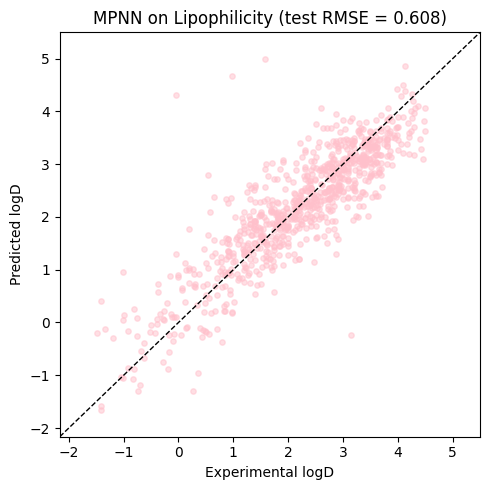

In [15]:
import matplotlib.pyplot as plt

lims = [min(y_test_true.min(), y_test_pred.min()) - 0.5, max(y_test_true.max(), y_test_pred.max()) + 0.5]

plt.figure(figsize=(5, 5))
plt.scatter(y_test_true, y_test_pred, alpha=0.5, s=15, c='pink')
plt.plot(lims, lims, 'k--', lw=1)
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Experimental logD")
plt.ylabel("Predicted logD")
plt.title(f"MPNN on Lipophilicity (test RMSE = {mean_squared_error(y_test_true, y_test_pred) ** 0.5:.3f})")
plt.tight_layout()
plt.show()

The dataset is strategically relatively small, so the model was trained very fast on collab's GPUs. Metrics for this simple GNN look better than everything before.